# AsthmaAware personalization model — v1 demo

This notebook runs the full v1 pipeline end to end:

1. **Pollutant grid** — hourly O3, NO2, SO2, PM2.5 over the Atlanta box, `[hours, 4, 25, 27]`
2. **Exposure** — the daily statistics the research coefficients were measured on, 3-day averaged
3. **General risk map** — `log(RR) = Σ β_p (level_p − clean-air level_p)` with Strickland et al. 2011 coefficients
4. **Personal model** — `severity = baseline + k·log(RR) + w·z`, 5 numbers per user, updated after every daily log
5. **Demo** — simulated users with known sensitivities: does the model learn them, and do their maps differ?

> **All pollution data here is synthetic.** The highways, urban core and SO2 source are invented. To use real data, replace `synthetic_grid()` with the upscaling pipeline's output in the same shape and units (see the last cell).

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from asthmaaware_v1 import (BETA, BBOX, POLLUTANTS, UNITS, HISTORY_HOURS,
                            PersonalModel, ReferenceStats, exposure, general_risk)
from asthmaaware_v1.synthetic import (default_personas, daily_user_exposure,
                                      simulate_logs, synthetic_grid)

# ---- plot styling (one-hue sequential ramps, fixed categorical order) ----
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SERIES = {"O3": "#2a78d6", "NO2": "#eb6834", "SO2": "#1baf7a", "PM25": "#eda100"}
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#6da7ec", "#2a78d6", "#1c5cab", "#0d366b"])
RISK = LinearSegmentedColormap.from_list("risk", ["#fdf1ea", "#f6b896", "#eb6834", "#b8461a", "#6e2509"])
LABEL = {"O3": "O₃", "NO2": "NO₂", "SO2": "SO₂", "PM25": "PM2.5"}
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "axes.titlecolor": INK, "axes.titlesize": 10,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})
EXTENT = [BBOX["west"], BBOX["east"], BBOX["south"], BBOX["north"]]

def show_map(ax, field, title, cmap, vmin=None, vmax=None, unit=""):
    im = ax.imshow(field, origin="lower", extent=EXTENT, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_title(title, loc="left")
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)
    cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
    cb.outline.set_visible(False); cb.ax.tick_params(labelsize=8, colors=INK2)
    if unit: cb.set_label(unit, color=INK2, fontsize=8)
    return im

## 1. Pollutant grid

Jan 1 – Jun 30 2023, hourly. Channel order is always O3 (ppb), NO2 (ppb), SO2 (ppb), PM2.5 (µg/m³). The coefficients assume **ground-level** concentrations in these units.

X shape: (4344, 4, 25, 27)   (hours, pollutants, rows, cols)
demo hour: 2023-06-28T16


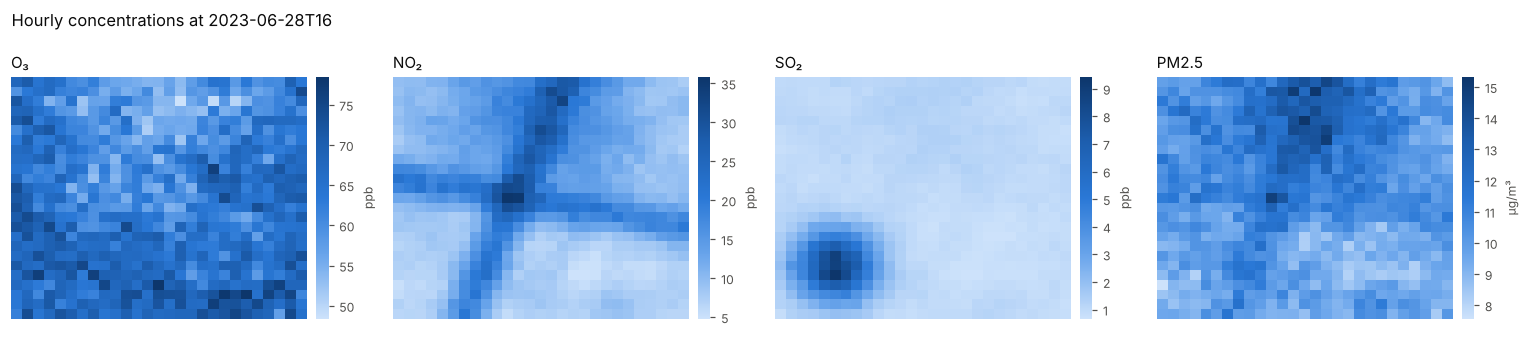

In [2]:
X, times = synthetic_grid(days=181, seed=0)
print("X shape:", X.shape, "  (hours, pollutants, rows, cols)")

# pick a demo day: a moderately bad ozone day in May–June (75th percentile, not the extreme)
day_o3 = X[:, 0].reshape(-1, 24, 25, 27).mean((1, 2, 3))
mj = np.arange(120, 181)
demo_day = int(mj[np.argsort(day_o3[mj])[int(0.75 * len(mj))]])
t_demo = demo_day * 24 + 16          # 4 pm on a spring ozone day

# a second demo day: a high-NO2 winter day (Jan–Feb, 90th percentile)
day_no2 = X[:, 1].reshape(-1, 24, 25, 27).mean((1, 2, 3))
jf = np.arange(4, 59)
winter_day = int(jf[np.argsort(day_no2[jf])[int(0.9 * len(jf))]])
t_winter = winter_day * 24 + 16
print("demo hour:", times[t_demo])

fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for c, p in enumerate(POLLUTANTS):
    show_map(axes[c], X[t_demo, c], LABEL[p], BLUES, unit=UNITS[c])
fig.suptitle(f"Hourly concentrations at {times[t_demo]}", x=0.01, ha="left", color=INK)
plt.tight_layout()

## 2. Exposure

At every hour, over the trailing 24 h: O3 highest 8-h mean, NO2 and SO2 highest 1-h value, PM2.5 24-h mean. Then average today, yesterday and the day before. The first 78 hours are blank because there isn't enough history yet.

Reference stats come from the whole Jan–Jun period: one mean/std **per pollutant** (for standardizing), and the 5th percentile as the clean-air level.

In [3]:
E = exposure(X)
ref = ReferenceStats.fit(E)
Z = ref.standardize(E)

print(f"history rows blanked: {np.isnan(E[:, 0, 0, 0]).sum()} (expected {HISTORY_HOURS})\n")
print(f"{'pollutant':10}{'mean':>8}{'std':>8}{'clean air':>11}  unit")
for c, p in enumerate(POLLUTANTS):
    print(f"{p:10}{ref.mean[c]:8.2f}{ref.std[c]:8.2f}{ref.clean[c]:11.2f}  {UNITS[c]}")

history rows blanked: 78 (expected 78)

pollutant     mean     std  clean air  unit
O3           36.62   11.74      20.78  ppb
NO2          20.16   11.75       7.88  ppb
SO2           2.83    2.76       1.12  ppb
PM25          9.95    2.36       6.51  µg/m³


## 3. General risk map

`log(RR)` per cell, using the Strickland coefficients. `RR = 1.25` means 25% more asthma ER visits than a clean-air day. The 0–100 score ranks each value against all of Jan–Jun 2023.

β per unit: {'O3': 0.00271, 'NO2': 0.00499, 'SO2': 0.00258, 'PM25': 0.00431}
RR across all cells & hours: median 1.12, 95th pct 1.29, max 1.82

cell (12,13) at demo hour: RR = 1.29
  NO2   +0.136 log-RR  (54%)
  O3    +0.087 log-RR  (34%)
  PM25  +0.030 log-RR  (12%)
  SO2   +0.002 log-RR  (1%)


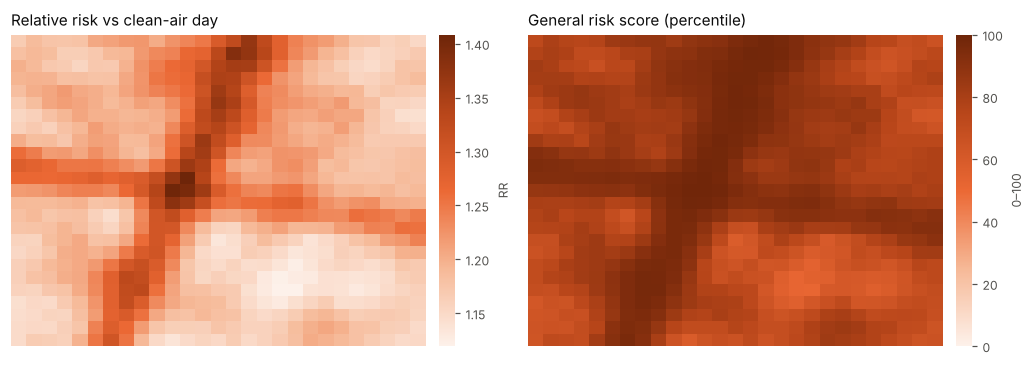

In [4]:
g = general_risk(E, ref)
print("β per unit:", {p: round(float(b), 5) for p, b in zip(POLLUTANTS, BETA)})
print(f"RR across all cells & hours: median {np.nanmedian(g.rr):.2f}, 95th pct {np.nanpercentile(g.rr, 95):.2f}, max {np.nanmax(g.rr):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
show_map(axes[0], g.rr[t_demo], "Relative risk vs clean-air day", RISK, unit="RR")
show_map(axes[1], g.score[t_demo], "General risk score (percentile)", RISK, 0, 100, unit="0–100")
plt.tight_layout()

# what's driving it at the centre of the map?
i, j = 12, 13
share = g.contributions[t_demo, :, i, j]
print(f"\ncell ({i},{j}) at demo hour: RR = {g.rr[t_demo, i, j]:.2f}")
for c in np.argsort(-share):
    print(f"  {POLLUTANTS[c]:5} {share[c]:+.3f} log-RR  ({100 * share[c] / share.sum():.0f}%)")

## 4. Personal model — simulated users

We don't have real users yet, so we invent three with **known** sensitivities, generate one 0–4 symptom log per day from the pollution at their location (with noise, rounded to whole numbers like a real app), and let the model learn.

`k = 3` is a placeholder team decision: the worst ~5% of hours add about 0.8 severity points over a clean day.

In [5]:
K = 3.0
rng = np.random.default_rng(42)
personas = default_personas()
results = {}

for u in personas:
    days, zb, eb = daily_user_exposure(Z, g.log_rr, u.cell)
    y = simulate_logs(u, zb, eb, K, rng)
    m = PersonalModel(k=K)
    hist_theta, hist_sd = [], []
    for d in range(len(y)):
        m.update(zb[d], eb[d], y[d])
        hist_theta.append(m.theta.copy()); hist_sd.append(np.sqrt(np.diag(m.cov)))
    results[u.name] = dict(user=u, model=m, zb=zb, eb=eb, y=y,
                           theta=np.array(hist_theta), sd=np.array(hist_sd))
    print(u.describe())
    print(f"   learned after {m.n_logs} logs: baseline {m.baseline:.2f}, w =",
          ", ".join(f"{p} {v:+.2f}±{s:.2f}" for p, v, s in zip(POLLUTANTS, m.w, m.w_sd)))

Typical user: baseline 1.2; no extra sensitivities
   learned after 177 logs: baseline 1.04, w = O3 -0.04±0.06, NO2 +0.03±0.05, SO2 -0.12±0.24, PM25 +0.06±0.06
Ozone-sensitive: baseline 1.3; O3 +0.80
   learned after 177 logs: baseline 1.43, w = O3 +0.79±0.05, NO2 +0.03±0.17, SO2 +0.17±0.26, PM25 +0.00±0.08
Traffic-sensitive: baseline 1.0; NO2 +0.70, PM25 +0.30
   learned after 177 logs: baseline 1.06, w = O3 +0.03±0.06, NO2 +0.64±0.07, SO2 +0.03±0.24, PM25 +0.29±0.06


### Does it learn the planted sensitivities?

Solid lines are the model's estimate after each log (shaded = ±1 std). Dashed lines are the true values we planted. SO₂ stays uncertain for most users because SO₂ barely changes where they live — the model correctly refuses to guess.

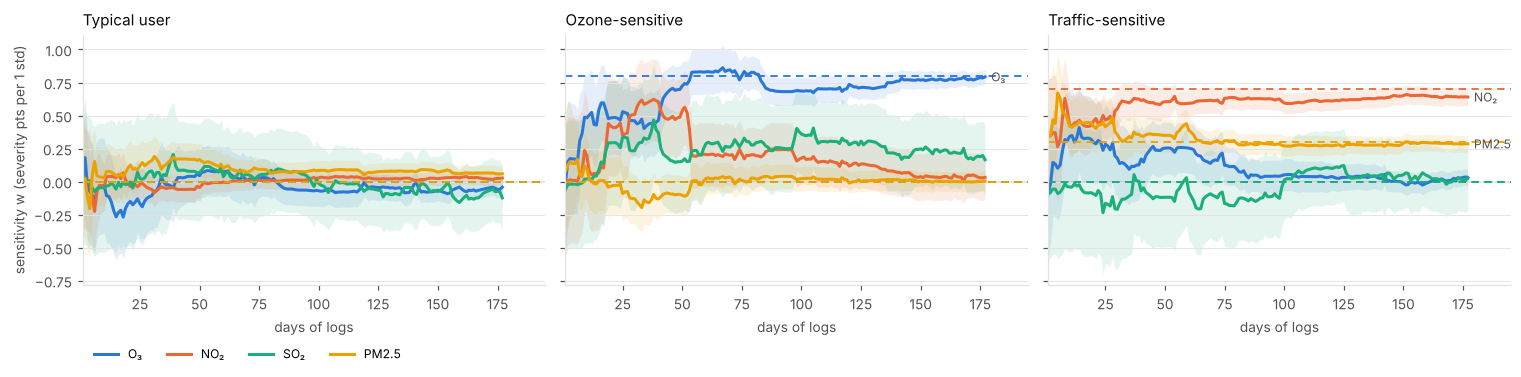

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, (name, r) in zip(axes, results.items()):
    n = np.arange(1, len(r["y"]) + 1)
    for c, p in enumerate(POLLUTANTS):
        est, sd, col = r["theta"][:, c + 1], r["sd"][:, c + 1], SERIES[p]
        ax.fill_between(n, est - sd, est + sd, color=col, alpha=0.12, lw=0)
        ax.plot(n, est, color=col, lw=2, label=LABEL[p])
        ax.axhline(r["user"].w[c], color=col, lw=1.2, ls=(0, (4, 3)))
        if r["user"].w[c] != 0:      # direct-label only the planted sensitivities
            ax.annotate(LABEL[p], (n[-1], est[-1]), xytext=(4, 0), textcoords="offset points",
                        va="center", fontsize=8, color=INK2)
    ax.axhline(0, color=GRID, lw=1, zorder=0)
    ax.set_title(name, loc="left"); ax.set_xlabel("days of logs")
    ax.set_xlim(1, n[-1] + 18); ax.grid(axis="y", color=GRID, lw=0.6)
axes[0].set_ylabel("sensitivity w (severity pts per 1 std)")
axes[0].legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.2), fontsize=8)
plt.tight_layout()

### Same day, different maps

All maps use the same 0–100 personal severity score (25 × predicted severity). A new user with no logs sees the general risk on the typical-user scale. Top row is a high-NO₂ winter day, bottom row a spring ozone day: the traffic-sensitive user's map lights up along the highways in winter, the ozone-sensitive user's map in spring.

Maps change from day to day more than hour to hour, because exposure uses trailing 24-hour statistics averaged over 3 days (that's how the research coefficients were measured).

**Known v1 limitation:** weights are learned from exposures at the user's own location, then applied to the whole map. The ozone-sensitive user never goes near the SO₂ source, so their learned SO₂ weight is mostly noise, yet it still shows up as a hotspot around that source in their winter map. v2 should shrink uncertain weights toward zero where exposures fall outside the user's experience.

2023-02-26 map-wide average score: {'New user (no logs)': 41.2, 'Typical user': 42.0, 'Ozone-sensitive': 48.8, 'Traffic-sensitive': 62.7}
2023-06-28 map-wide average score: {'New user (no logs)': 39.2, 'Typical user': 39.5, 'Ozone-sensitive': 86.9, 'Traffic-sensitive': 47.6}


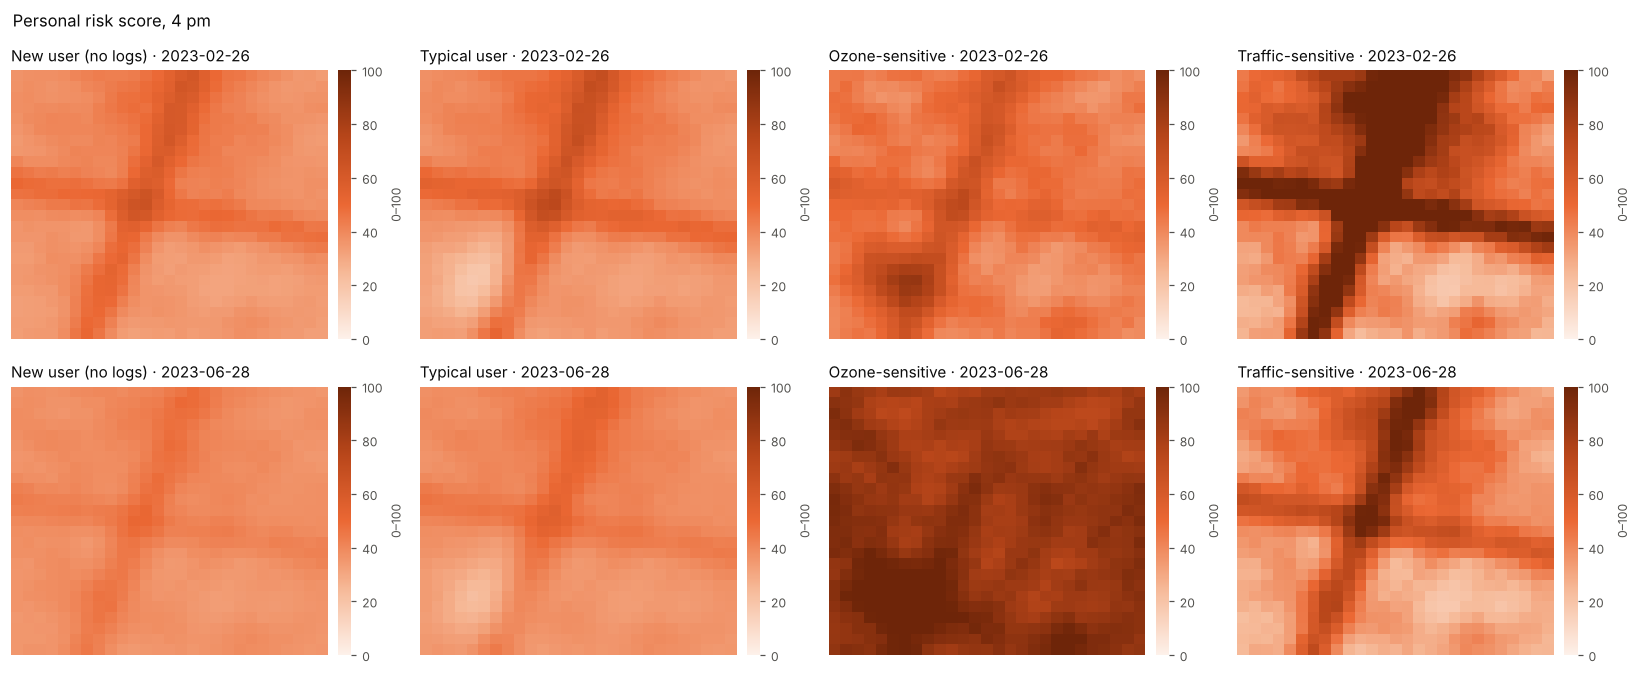

In [7]:
models = {"New user (no logs)": PersonalModel(k=K), **{n: r["model"] for n, r in results.items()}}
rows = [(t_winter, str(times[t_winter])[:10]), (t_demo, str(times[t_demo])[:10])]

fig, axes = plt.subplots(2, 4, figsize=(15, 6.2))
for row, (t, label) in enumerate(rows):
    sl = slice(t, t + 1)
    for col, (name, m) in enumerate(models.items()):
        mp = m.predict(Z[sl], g.log_rr[sl])["score"][0]
        show_map(axes[row, col], mp, f"{name} · {label}", RISK, 0, 100, unit="0–100")
fig.suptitle("Personal risk score, 4 pm", x=0.01, ha="left", color=INK)
plt.tight_layout()

for t, label in rows:
    sl = slice(t, t + 1)
    avg = {n: round(float(m.predict(Z[sl], g.log_rr[sl])["score"].mean()), 1) for n, m in models.items()}
    print(f"{label} map-wide average score:", avg)

### Top factors and the "still learning" banner

What each user would see on the dashboard for their own location at the demo hour. Contributions are exact (the model is linear): general effect `k·β·(level − clean)` plus personal extra `w·z`.

In [8]:
def band(score):
    return "low" if score <= 30 else "moderate" if score <= 60 else "high"

sl = slice(t_demo, t_demo + 1)
for name, r in results.items():
    m, u = r["model"], r["user"]
    i, j = u.cell
    pred = m.predict(Z[sl, :, i:i+1, j:j+1], g.log_rr[sl, i:i+1, j:j+1])
    s, sd = float(pred["score"][0, 0, 0]), float(pred["sd"][0, 0, 0])
    tops = m.top_factors(Z, E, ref, t_demo, u.cell)
    print(f"{name} @ cell {u.cell}: score {s:.0f} ({band(s)}), severity ±{sd:.2f}")
    print("   top factors:", ", ".join(f"{LABEL[p]} {v:+.2f}" for p, v in tops))

# the banner turns off once predictions on days like theirs are confident
print()
for name, r in results.items():
    m_early = PersonalModel(k=K)
    for d in range(len(r["y"])):
        m_early.update(r["zb"][d], r["eb"][d], r["y"][d])
        if not m_early.still_learning(r["zb"][max(0, d - 13):d + 1]):
            print(f"{name}: 'still learning' banner off after {d + 1} logs")
            break
    else:
        print(f"{name}: still learning after {len(r['y'])} logs")

Typical user @ cell (12, 13): score 48 (moderate), severity ±0.60
   top factors: NO₂ +0.44, O₃ +0.20, PM2.5 +0.17
Ozone-sensitive @ cell (6, 20): score 85 (high), severity ±0.60
   top factors: O₃ +1.97, PM2.5 +0.05, NO₂ +0.00
Traffic-sensitive @ cell (14, 9): score 65 (high), severity ±0.60
   top factors: NO₂ +0.82, PM2.5 +0.43, O₃ +0.30

Typical user: 'still learning' banner off after 25 logs
Ozone-sensitive: 'still learning' banner off after 24 logs
Traffic-sensitive: 'still learning' banner off after 27 logs


## 5. Storage

What the backend keeps per user: 5 numbers' worth of state (a 5×5 matrix and a 5-vector) plus hyperparameters. Updating after a log is a few microseconds.

In [9]:
state = results["Ozone-sensitive"]["model"].to_dict()
print(f"{len(json.dumps(state))} bytes as JSON")
restored = PersonalModel.from_dict(state)
assert np.allclose(restored.theta, results["Ozone-sensitive"]["model"].theta)
print("round-trip OK; theta =", restored.theta.round(3))

722 bytes as JSON
round-trip OK; theta = [1.432 0.793 0.032 0.165 0.004]


## Plugging in real data

Replace the `synthetic_grid()` call with the upscaling pipeline's output:

```python
X = np.load("forecast_cube.npy")   # [T, 4, 25, 27], channels O3, NO2, SO2, PM2.5
```

Requirements:
- **Units:** ground-level ppb (O3, NO2, SO2) and µg/m³ (PM2.5). Satellite column densities or AOD will make the coefficients meaningless.
- **History:** at least 78 hours before the first hour you need a map for.
- **Reference stats:** fit `ReferenceStats` once on the real Jan–Jun 2023 cube, `ref.save("ref.npz")`, and load it in production.
- **Grid:** any H × W works; only the bounding-box helpers assume 25 × 27.

Open team decisions: the value of `k`, and the priors (`prior_baseline`, `prior_sd_w`, `sigma2`).